# 随机森林与集成学习

本 Notebook 对应讲义“随机森林”部分，包含：

1. 单棵决策树的过拟合与不稳定性；
2. 自助采样、六棵树与多数投票；
3. 集成学习“好而不同”的条件；
4. Bagging、随机森林、AdaBoost；
5. 袋外样本 OOB；
6. 多树投票准确率与相关性的关系；
7. 讲义原图、函数和解释。

数据由 `make_2d()` 生成：训练集 200 人、验证集 600 人，两个特征为月收入（千元）和负债收入比，约 12% 的标签被随机翻转，模拟噪声。


In [1]:
# %matplotlib inline

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
Path("images").mkdir(exist_ok=True)


def make_2d(seed=273, n=800):
    """生成二维二分类数据：月收入、负债收入比，并加入约 12% 标签噪声。"""
    r = np.random.default_rng(seed)
    inc = np.round(r.uniform(3, 25, n), 1)
    debt = np.round(np.clip(r.beta(2.2, 3, n), 0.01, 0.99), 3)

    # 真实规则：高负债或低收入高负债的人更容易违约
    risky = (debt > 0.22 + 0.022 * inc) | ((inc < 6) & (debt > 0.2))
    # 异或：约 12% 的样本标签翻转，制造噪声
    y = (risky ^ (r.random(n) < 0.12)).astype(int)

    X = np.c_[inc, debt]
    return X[:200], y[:200], X[200:], y[200:]


X2, y2, Xv2, yv2 = make_2d()

# 不限制深度：让单棵树尽可能长满
full = DecisionTreeClassifier(random_state=0).fit(X2, y2)
full_acc = full.score(Xv2, yv2)

print("叶子数量:", full.get_n_leaves())
print("训练准确率:", round(full.score(X2, y2), 4))
print("验证准确率:", round(full_acc, 4))


叶子数量: 53
训练准确率: 1.0
验证准确率: 0.7067


## 1. 单棵决策树：训练集满分，验证集拉胯

不剪枝的决策树会一直分裂，直到每个叶子尽量纯净。结果：

- 训练准确率 **1.0000**；
- 验证准确率约 **0.7067**；
- 叶子多达 53 片。

训练集满分并不代表学到了规律，而是把噪声也背了下来，这是典型的过拟合。单棵树的方差很大，数据稍微变化，树结构就可能大幅改变。

单棵树的决策边界、以及数据变化后边界如何改变，见下一节讲义中的三面板对比图。


## 2. 数据轻微变化，树就变了

从 200 个训练样本中随机删掉 10 个人，只用剩下的 190 人重新训练一棵树，再对比两棵树在整个特征平面上的预测。

如果两棵树的判断几乎一样，说明模型稳定；如果大片区域发生反转，说明单棵树对训练数据非常敏感。


In [2]:
# 1. 生成网格，扫描月收入 3~25、负债收入比 0~1 的平面
gx, gy = np.meshgrid(np.linspace(3, 25, 66), np.linspace(0, 1, 48))
grid = np.c_[gx.ravel(), gy.ravel()]

# 2. 随机保留 190 个样本，丢掉 10 个
keep = np.sort(np.random.default_rng(11).permutation(200)[:190])

# 3. 用剩下的 190 个样本重新训练一棵树
pert = DecisionTreeClassifier(random_state=0).fit(X2[keep], y2[keep])

# 4. 对比两棵树在网格上的预测，统计判断反转的区域占比
changed = np.mean(full.predict(grid) != pert.predict(grid))
print(
    f"拿掉10人（5%）后：叶子{pert.get_n_leaves()}，"
    f"验证准确率 {pert.score(Xv2, yv2):.4f}；"
    f"平面上判断变化区域占比 {changed:.1%}"
)

拿掉10人（5%）后：叶子46，验证准确率 0.7333；平面上判断变化区域占比 12.9%


### 图 1-1  只拿掉 10 个人，树就大变样

下面用代码重新生成讲义中的三面板图：原始树、拿掉 10 人后重新训练的树、以及两棵树判断不同的区域。

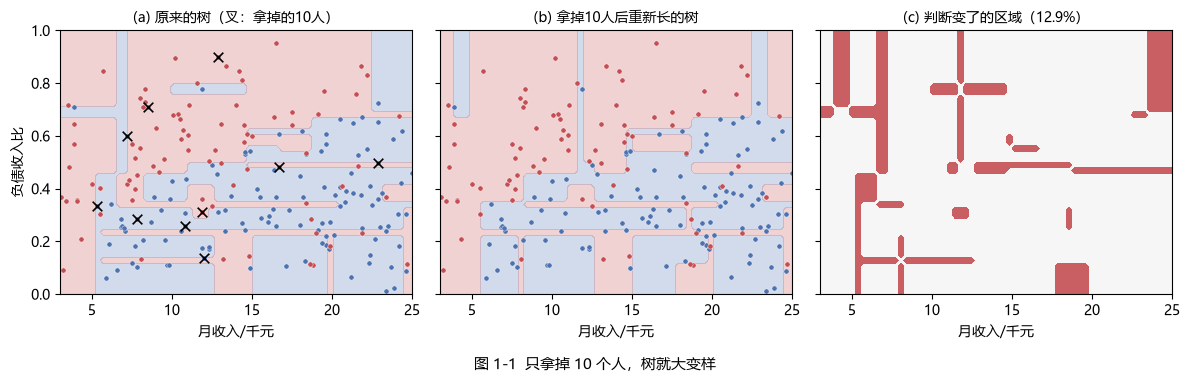

In [3]:
# 讲义三面板图：原始树、重新训练树、判断变化区域
removed = np.setdiff1d(np.arange(len(X2)), keep)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)

# (a) 原来的树：所有训练样本；叉号标出被拿掉的 10 人
zz_a = full.predict(grid).reshape(gx.shape)
axes[0].contourf(
    gx, gy, zz_a,
    levels=[-0.5, 0.5, 1.5],
    colors=["#4C72B0", "#C44E52"],
    alpha=0.25,
)
axes[0].scatter(X2[y2 == 0, 0], X2[y2 == 0, 1], s=14, c="#4C72B0",
                edgecolor="white", linewidth=0.3)
axes[0].scatter(X2[y2 == 1, 0], X2[y2 == 1, 1], s=14, c="#C44E52",
                edgecolor="white", linewidth=0.3)
axes[0].scatter(X2[removed, 0], X2[removed, 1], marker="x", s=48,
                c="black", linewidths=1.2, label="拿掉的10人")
axes[0].set_title("(a) 原来的树（叉：拿掉的10人）", fontsize=10)

# (b) 拿掉 10 人后重新训练的树：只画剩下的 190 人
zz_b = pert.predict(grid).reshape(gx.shape)
axes[1].contourf(
    gx, gy, zz_b,
    levels=[-0.5, 0.5, 1.5],
    colors=["#4C72B0", "#C44E52"],
    alpha=0.25,
)
axes[1].scatter(X2[keep][y2[keep] == 0, 0], X2[keep][y2[keep] == 0, 1],
                s=14, c="#4C72B0", edgecolor="white", linewidth=0.3)
axes[1].scatter(X2[keep][y2[keep] == 1, 0], X2[keep][y2[keep] == 1, 1],
                s=14, c="#C44E52", edgecolor="white", linewidth=0.3)
axes[1].set_title("(b) 拿掉10人后重新长的树", fontsize=10)

# (c) 两棵树判断不同的区域
mismatch = (full.predict(grid) != pert.predict(grid)).reshape(gx.shape)
axes[2].contourf(
    gx, gy, mismatch,
    levels=[-0.5, 0.5, 1.5],
    colors=["#F5F5F5", "#C44E52"],
    alpha=0.9,
)
axes[2].set_title(f"(c) 判断变了的区域（{changed:.1%}）", fontsize=10)

for ax in axes:
    ax.set_xlabel("月收入/千元")
    ax.set_xlim(3, 25)
    ax.set_ylim(0, 1)
axes[0].set_ylabel("负债收入比")

fig.text(0.5, -0.04, "图 1-1  只拿掉 10 个人，树就大变样",
         ha="center", fontsize=11)
fig.tight_layout()
fig.savefig("images/rf_instability_3panel.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. 六份自助样本：让六棵树投票

**自助采样（Bootstrap）**：从 200 个训练样本中有放回地抽 200 次，得到一份和原数据同样大小的采样集。有人会被重复抽到，也有人一次都抽不到。

重复 6 次，得到 6 份不同的自助样本，每份训练一棵树。单棵树都不算强，但它们犯错的位置不完全一样。把 6 棵树的预测放在一起做**多数投票**，错误就有机会互相抵消。


In [4]:
votes, accs = [], []

for i in range(6):
    idx = np.random.default_rng(200 + i).integers(0, 200, 200)
    m = DecisionTreeClassifier(random_state=0).fit(X2[idx], y2[idx])
    accs.append(round(m.score(Xv2, yv2), 4))
    votes.append(m.predict(Xv2))

votes = np.array(votes)       # 形状 (6, 600)：6 棵树 × 600 个验证样本
who = 94                       # 挑一个申请人，单独展示 6 棵树的分歧


def majority_vote(votes):
    """多数投票：票数超过一半判为 1；6 棵树时 3:3 平票按 0 处理。"""
    counts = votes.sum(axis=0)
    return (counts > votes.shape[0] / 2).astype(int)


counts = votes.sum(axis=0)
maj = majority_vote(votes)
ensemble_acc = (maj == yv2).mean()
mean_single_acc = np.mean(accs)
tie_rate = np.mean(counts == 3)
disagree_rate = np.mean((counts != 0) & (counts != 6))

print("6棵树的验证准确率:", accs)
print(f"6棵树平均准确率: {mean_single_acc:.4f}")
print(f"6棵树多数投票准确率: {ensemble_acc:.4f}")
print(f"3:3 平票的样本占比: {tie_rate:.1%}")
print(f"意见不统一（不是 6:0 或 0:6）的样本占比: {disagree_rate:.1%}")
print(
    f"申请人（月收入{Xv2[who,0]}千，负债收入比{Xv2[who,1]}，"
    f"实际{'违约' if yv2[who] else '正常'}）："
    f"6棵树的判断 {votes[:, who]}"
)

6棵树的验证准确率: [0.7117, 0.6567, 0.7, 0.7267, 0.7317, 0.7433]
6棵树平均准确率: 0.7117
6棵树多数投票准确率: 0.7667
3:3 平票的样本占比: 11.0%
意见不统一（不是 6:0 或 0:6）的样本占比: 53.3%
申请人（月收入21.0千，负债收入比0.117，实际正常）：6棵树的判断 [0 0 1 0 1 1]


## 4. 集成学习：好而不同

集成学习（ensemble learning）先训练一批个体学习器（基学习器），再用一套规则合并结果：

- 分类：多数投票，票数最多的类别获胜；
- 回归：取所有基学习器输出的平均值。

多数投票要生效，基学习器必须满足两个条件：

| 条件 | 含义 |
|---|---|
| **好** | 每个学习器至少比随机猜略强 |
| **不同** | 它们犯错的位置不要完全一样 |

如果所有学习器一模一样，投票等于只投了一次；如果每个学习器都比瞎猜还差，投票只会把错误放大。


## 5. Bagging：分头行动，独立投票

**Bagging**（Bootstrap AGGregatING，装袋）：

1. 用自助采样得到多份训练子集；
2. 每份训练一棵基学习器，树与树之间独立；
3. 分类时每棵树一票，多数投票；回归时取平均；
4. 可以并行训练。

它主要降低模型**方差**，适合“强但不稳定”的深决策树。


In [5]:
from sklearn.ensemble import BaggingClassifier

bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=100,
    random_state=0,
).fit(X2, y2)

bag_acc = bag.score(Xv2, yv2)
print("单棵不剪枝树验证准确率:", round(full_acc, 4))
print("100棵树 Bagging 验证准确率:", round(bag_acc, 4))
print("基学习器数量:", len(bag.estimators_))


单棵不剪枝树验证准确率: 0.7067
100棵树 Bagging 验证准确率: 0.805
基学习器数量: 100


## 6. 随机森林：Bagging 的加强版

Bagging 只随机样本，每次分裂仍然可以使用全部特征。**随机森林**在此基础上再加一层随机：每次分裂只随机考虑一部分特征。

两套随机手段：

1. **样本随机**：每棵树使用不同的自助采样集；
2. **特征随机**：每次节点分裂只从随机子集中选特征。

这样树与树之间的相关性更低，投票更有效。随机森林还可以用**袋外样本（OOB）**评估泛化效果，不必额外切验证集。


In [6]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    oob_score=True,
    random_state=0,
    n_jobs=-1,
).fit(X2, y2)

rf_acc = rf.score(Xv2, yv2)
print("随机森林验证准确率:", round(rf_acc, 4))
print("OOB 分数:", round(rf.oob_score_, 4))
print("特征重要性:", {
    "月收入": round(float(rf.feature_importances_[0]), 4),
    "负债收入比": round(float(rf.feature_importances_[1]), 4),
})


随机森林验证准确率: 0.8017
OOB 分数: 0.76
特征重要性: {'月收入': 0.4501, '负债收入比': 0.5499}


## 7. Boosting：接力纠错

Bagging 是“分头行动、平等投票”；Boosting 是“接力纠错、加权投票”：

1. 先训练一个弱学习器（例如只分裂一次的树桩）；
2. 提高被它分错样本的权重；
3. 下一个学习器重点学习这些错分样本；
4. 重复多轮；
5. 最终按学习器的好坏加权投票，效果好的权重大。

Boosting 主要降低**偏差**，把很多弱学习器逐步拼成一个强学习器。

| 对比项 | Bagging | Boosting / AdaBoost |
|---|---|---|
| 训练方式 | 并行、互相独立 | 串行、后一棵依赖前一轮 |
| 样本 | 自助采样 | 不重新采样，调整样本权重 |
| 投票 | 平等投票 | 加权投票 |
| 目标 | 降低方差 | 降低偏差 |
| 典型基学习器 | 深决策树 | 树桩等弱学习器 |


In [7]:
from sklearn.ensemble import AdaBoostClassifier

stump = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X2, y2)
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=0),
    n_estimators=100,
    random_state=0,
).fit(X2, y2)

stump_acc = stump.score(Xv2, yv2)
ada_acc = ada.score(Xv2, yv2)
print("一棵树桩验证准确率:", round(stump_acc, 4))
print("100棵树桩 AdaBoost 验证准确率:", round(ada_acc, 4))


一棵树桩验证准确率: 0.7083
100棵树桩 AdaBoost 验证准确率: 0.755


## 8. 自助采样与袋外样本

从 \(n\) 条训练样本中有放回抽 \(n\) 次，某个样本一次都没被抽中的概率是：

$$
\left(1-\frac{1}{n}\right)^n
$$

当 \(n\to\infty\) 时：

$$
\left(1-\frac{1}{n}\right)^n \to \frac{1}{e}\approx 0.368
$$

所以每份自助采样集平均只覆盖约 **63.2%** 的不同样本，剩下约 **36.8%** 是袋外样本（OOB）。这些袋外样本没有参与这棵树的训练，可以直接用来评估泛化效果，这是 Bagging 和随机森林特有的便利。


In [8]:
def simulate_oob(n, trials=2000, seed=0):
    """模拟 n 次有放回抽样，返回袋外样本比例的平均值。"""
    rng = np.random.default_rng(seed)
    ratios = [
        np.mean(np.bincount(rng.integers(0, n, n), minlength=n) == 0)
        for _ in range(trials)
    ]
    return float(np.mean(ratios))


oob_results = {
    n: simulate_oob(n, trials=2000 if n < 1000 else 300)
    for n in [16, 100, 1000]
}
for n, ratio in oob_results.items():
    print(
        f"n={n:>4}: 模拟袋外比例 {ratio:.4f}，"
        f"公式 (1-1/n)^n = {(1 - 1/n)**n:.4f}"
    )
print("1/e =", round(float(np.exp(-1)), 4))

n=  16: 模拟袋外比例 0.3543，公式 (1-1/n)^n = 0.3561
n= 100: 模拟袋外比例 0.3648，公式 (1-1/n)^n = 0.3660
n=1000: 模拟袋外比例 0.3674，公式 (1-1/n)^n = 0.3677
1/e = 0.3679


## 9. 为什么树越多不一定越好

假设每棵树单独预测正确的概率为 \(p\)，树与树之间相互独立。多数投票下，整体正确的概率为：

$$
P(\text{集成正确})
= \sum_{k=\lfloor n/2\rfloor+1}^{n}
\binom{n}{k}p^k(1-p)^{n-k}
$$

如果 \(p=0.6\)，独立投票时：

- 25 棵树：整体准确率约 0.846；
- 101 棵树：整体准确率约 0.979。

但前提是树之间尽量独立。若树高度相关，大家会在同一批样本上一起犯错，投票就失去意义。随机森林用“样本随机 + 特征随机”来降低相关性。

`vote_acc()` 用二项分布计算独立情形；当相关系数 \(\rho>0\) 时，用贝塔-二项分布近似。


In [9]:
from scipy.stats import binom, betabinom


def vote_acc(n, p, rho=0.0):
    """多数投票的集成准确率。

    n: 树的数量（建议取奇数）
    p: 单棵树答对的概率
    rho: 树与树之间的相关系数，0 表示完全独立
    """
    if rho == 0:
        return binom.sf(n // 2, n, p)

    # 相关系数越大，分布越集中，投票带来的提升越小
    s = 1 / rho - 1
    return betabinom.sf(n // 2, n, p * s, (1 - p) * s)


for rho in [0, 0.1, 0.3]:
    parts = [f"n={n}: {vote_acc(n, 0.6, rho):.3f}" for n in [1, 5, 25, 101]]
    print(f"rho={rho}: " + ", ".join(parts))

rho=0: n=1: 0.600, n=5: 0.683, n=25: 0.846, n=101: 0.979
rho=0.1: n=1: 0.600, n=5: 0.655, n=25: 0.708, n=101: 0.728
rho=0.3: n=1: 0.600, n=5: 0.626, n=25: 0.639, n=101: 0.642


## 小结

- 单棵不剪枝树：训练集 1.0000，验证集约 0.7067，叶子 53 片，方差大、易过拟合；
- 数据只删 5%，决策边界就有 **12.9%** 的区域发生反转；
- 6 棵自助树：单树准确率 0.657~0.743，多数投票提升到约 0.767；
- Bagging（100 棵）约 0.805；随机森林约 0.802，OOB 约 0.760；
- AdaBoost（100 个树桩）约 0.755；
- Bagging / 随机森林主要降方差，Boosting 主要降偏差；
- 投票要有效，基学习器必须“好而不同”；相关性越高，增加树的数量带来的收益越有限；
- OOB 比例约为 \((1-1/n)^n\)，当 n 很大时趋近 \(1/e\approx 36.8\%\)。

具体数值会随随机种子、数据噪声和 sklearn 版本略有变化，但结论不变：**单棵树不稳定，集成靠“好而不同”的多样性降低错误。**
